# Decorrelation Analysis v3: Distance-Decay Gaussian Fitting with Offset

This notebook performs a spatial decorrelation analysis for Dissolved Oxygen (DO) concentrations in the Seto Inland Sea. 

**Objective**:
Calculate the decorrelation scale ($d_x$) for each station individually by fitting a Gaussian decay model with offset to the correlation-distance relationships.

**Methodology**:
1.  **Data Preparation**: Load processed data, filter for Summer season and Bottom layer.
2.  **Distance Calculation**: Project coordinates to UTM Zone 53N (EPSG:32653) and calculate Euclidean distances.
3.  **Decorrelation Analysis**: 
    - For each station, calculate pairwise correlations with all other stations.
    - Fit a Gaussian model with offset: $r(x) = A \cdot \exp(-x^2/dx^2) + B$ where $A + B = 1$.
    - Determine decorrelation scale as the distance where correlation drops to $r_{crit}$ (p < 0.01).
4.  **Visualization**: Generate individual station plots and summary maps.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Apply the global project style as per SIS Mapping Standard
plt.style.use('../../project_style.mplstyle')
import seaborn as sns
import geopandas as gpd
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy import stats
from pathlib import Path
import warnings
import sys
import os
import yaml # Add this

# Ensure local scripts are importable
current_dir = Path(os.getcwd()).resolve()
project_root = current_dir.parent.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

warnings.filterwarnings('ignore')

In [3]:
# Parameters
r_crit_alpha = 0.01
distance_cutoff_km = 100
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom')) 

# --- Dynamic Regional Filtering ---
with open(project_root / 'params.yaml', 'r') as f:
    params = yaml.safe_load(f)
TARGET_REGION = params['mapping']['target_region']
REGION_COLUMN = params['mapping']['region_column']
# ---------------------------------


## 1. Data Loading and Preparation

We begin by loading the processed dataset `merged_gdf.feather`. We filter the data to retain only the observations relevant for our analysis: **Summer** season and **Bottom** layer (`saisuipoin == 2`). 
We then aggregate the data to calculate the yearly mean Dissolved Oxygen (`do_`) for each station (`zettaicode`).

In [4]:
# Load station geometry from merged data
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# --- Apply Regional Filter ---
if TARGET_REGION != "Seto Inland Sea":
    print(f"Filtering for region: {TARGET_REGION}")
    merged_gdf = merged_gdf[merged_gdf[REGION_COLUMN] == TARGET_REGION].copy()
# -----------------------------

# Load yearly DO data from seasonal subset
subset_path = Path(subset_dir)
yearly_do_df = pd.read_csv(subset_path / 'yearly_do_df.csv', index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

# --- Align DO data with filtered region ---
# This ensures stations outside the target region are dropped even if 
# they were present in the seasonal subset file
valid_stations = merged_gdf['zettaicode'].unique()
yearly_do_df = yearly_do_df[yearly_do_df.index.isin(valid_stations)].copy()
# ------------------------------------------

# Extract unique station locations for remaining stations
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]  # Ensure alignment

print(f"Region: {TARGET_REGION}")
print(f"Stations in analysis: {len(yearly_do_df)}")
display(yearly_do_df.head())

Region: Seto Inland Sea
Stations in analysis: 124


,1982,1984,1985,1986,1987,1988,1989,1990,1991,1992,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
zettaicode,,,,,,,,,,,,,,,,,,,,,
00000272,4.0,1.1,1.9,2.1,0.8,2.9,2.1,1.5,0.9,1.2,...,0.5,0.5,0.6,0.7,1.1,1.1,0.8,1.1,0.5,1.4
00000275,1.1,1.5,0.7,3.1,0.0,1.1,1.4,0.3,1.1,1.0,...,0.5,0.6,0.5,0.5,0.6,0.8,2.3,0.6,0.5,1.2
00002725,5.6,4.8,3.9,9.5,6.2,5.0,5.5,5.9,7.2,3.0,...,6.2,6.1,5.9,2.9,6.6,6.6,3.1,6.4,6.5,6.8
00002737,6.8,5.4,5.1,6.6,6.0,4.7,6.0,4.6,4.9,7.5,...,6.5,5.5,6.0,6.2,6.1,7.6,6.9,5.3,4.9,6.3
00002744,6.6,3.6,4.8,5.8,5.8,5.5,5.6,6.4,5.3,4.3,...,5.9,6.3,5.8,6.7,6.2,6.5,6.0,6.1,6.4,7.2


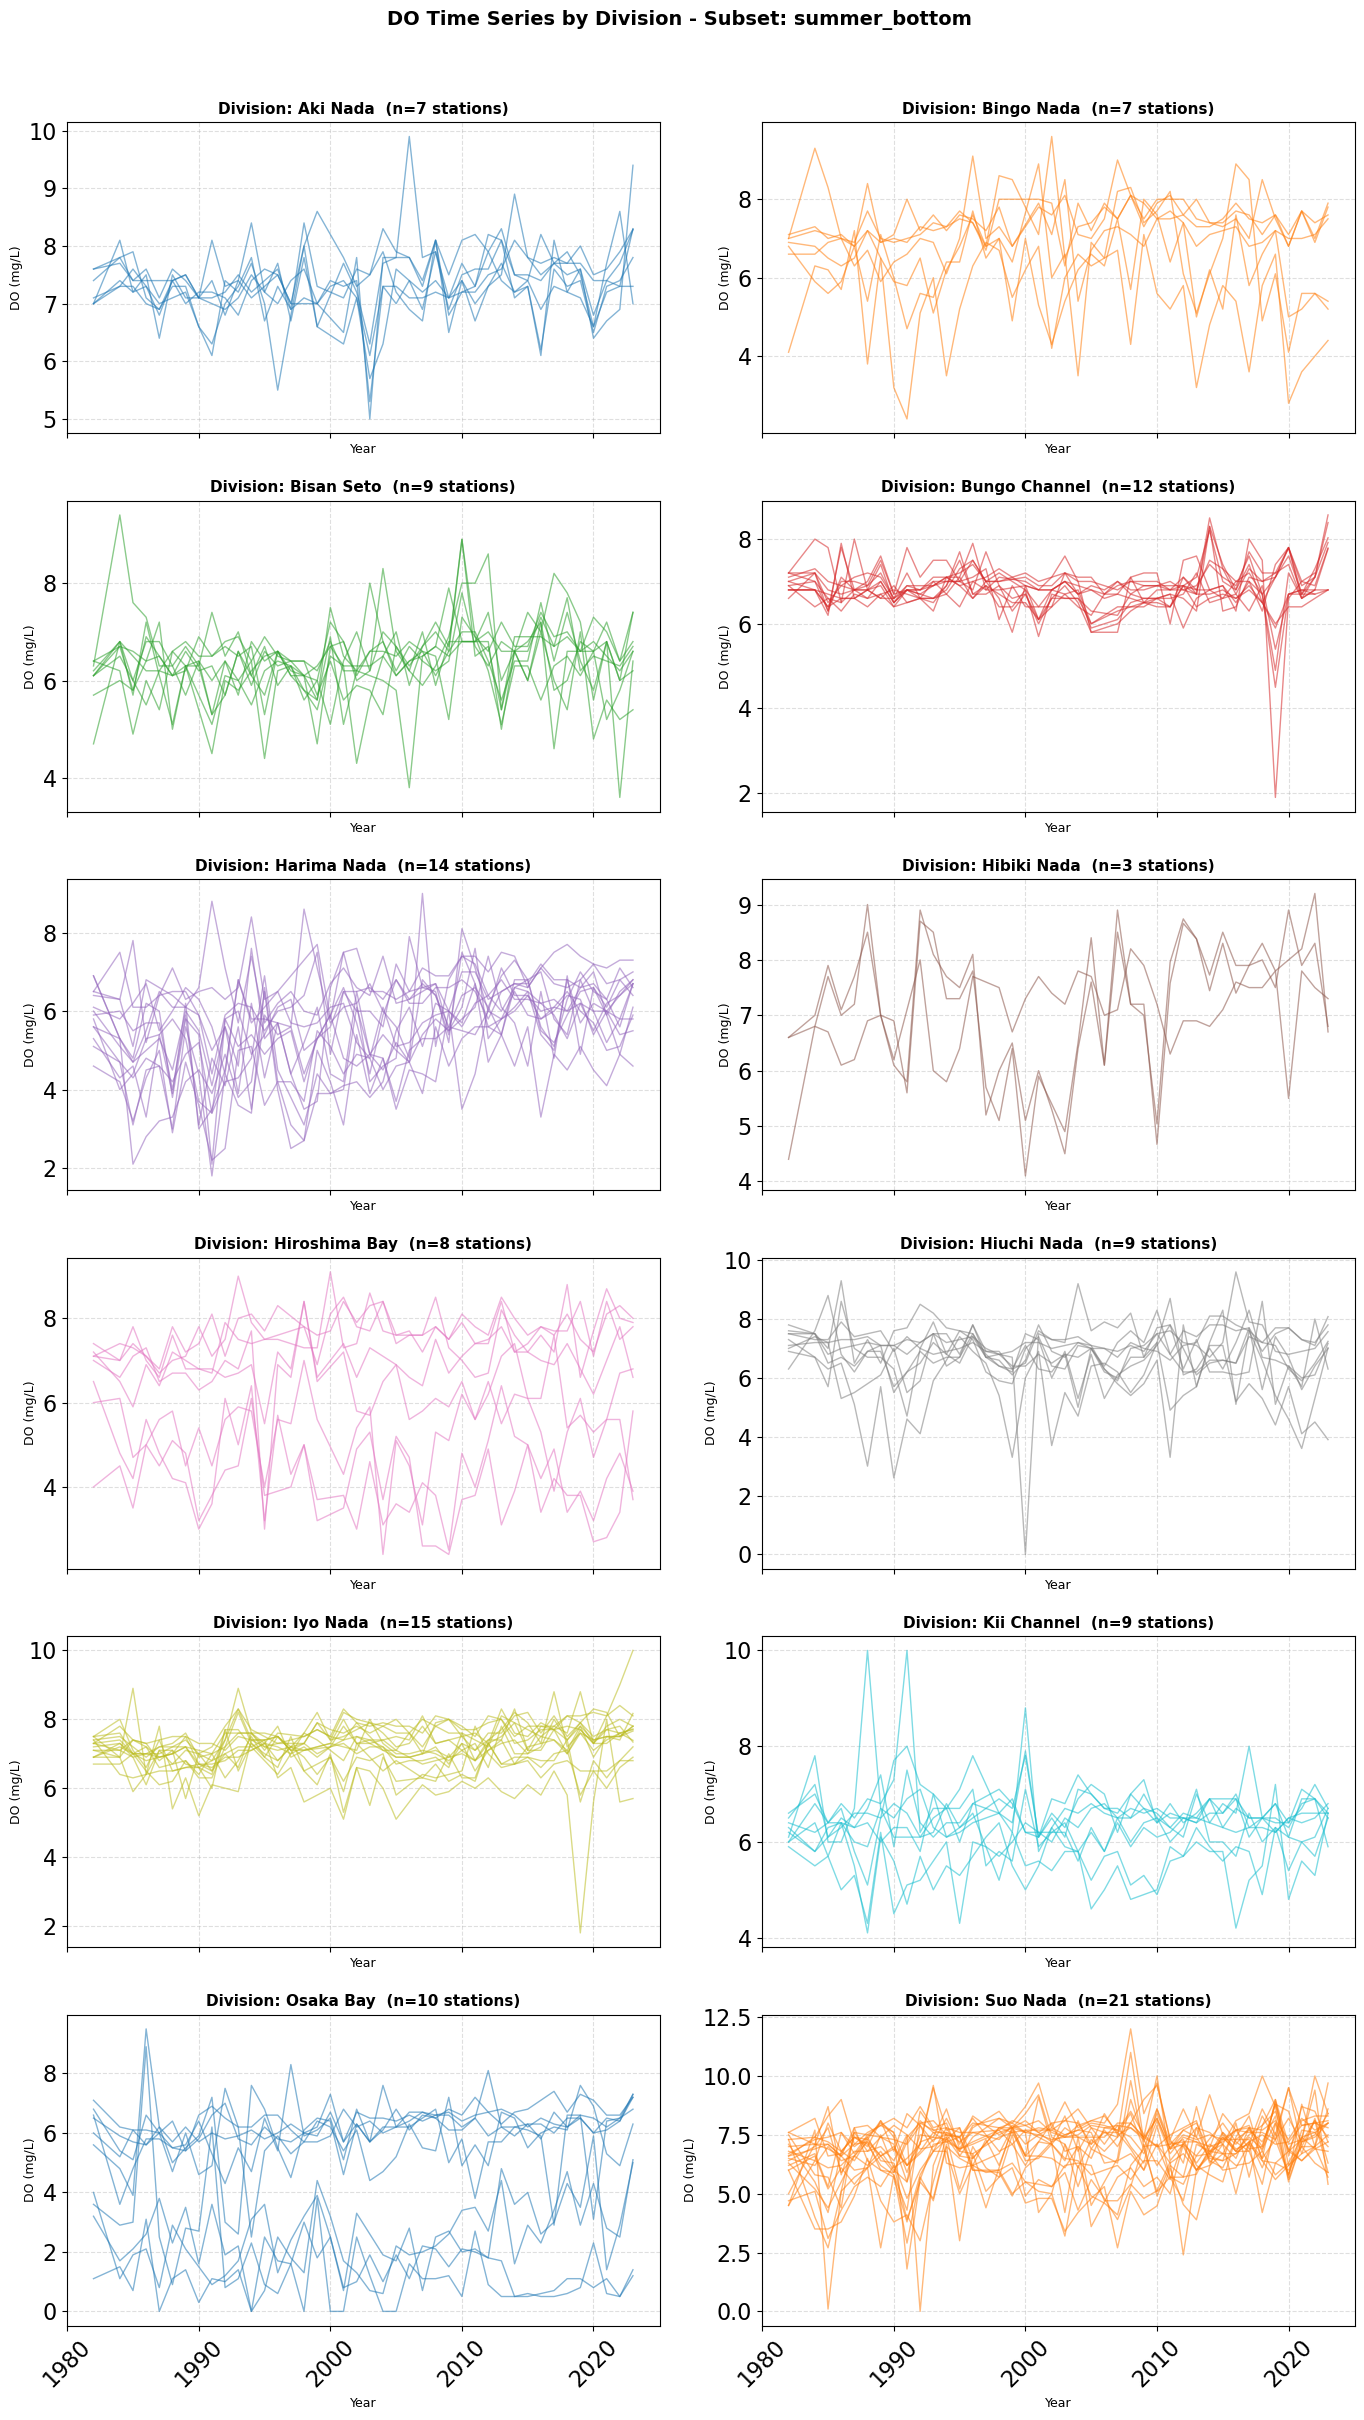

In [5]:
# ── Time Series: DO by Division (Water Mass) ─────────────────────────

# 1. Build a station → division lookup from merged_gdf (handles any seasonal subset)
station_division = (
    merged_gdf[['zettaicode', 'division']]
    .drop_duplicates('zettaicode')
    .set_index('zettaicode')['division']
)

# 2. Align with yearly_do_df (stations that survived the subset analysis)
station_division = station_division.reindex(yearly_do_df.index)

# 3. Get sorted list of divisions for consistent colour assignment
divisions = sorted(station_division.dropna().unique())

# 4. Colour palette – one colour per division
palette = sns.color_palette("tab10", n_colors=len(divisions))
div_colour = dict(zip(divisions, palette))

# 5. Build a long-form DataFrame for easy plotting
yearly_long = (
    yearly_do_df
    .reset_index()
    .rename(columns={'index': 'zettaicode'})  # In case index is named differently
    .melt(id_vars='zettaicode', var_name='year', value_name='do_')
)
yearly_long['division'] = yearly_long['zettaicode'].map(station_division)
yearly_long['year'] = pd.to_numeric(yearly_long['year'], errors='coerce')

# 6. Plot – one subplot per division
ncols = 2
nrows = -(-len(divisions) // ncols)   # ceiling division

fig, axes = plt.subplots(nrows, ncols,
                         figsize=(14, 4 * nrows),
                         sharey=False, sharex=True)
axes = axes.flatten()

for ax, div in zip(axes, divisions):
    div_data = yearly_long[yearly_long['division'] == div]
    stations_in_div = div_data['zettaicode'].unique()

    for station in stations_in_div:
        stn_data = div_data[div_data['zettaicode'] == station].dropna(subset=['do_'])
        ax.plot(
            stn_data['year'], stn_data['do_'],
            color=div_colour[div],
            alpha=0.55, linewidth=1.0, label=station
        )

    ax.set_title(f'Division: {div}  (n={len(stations_in_div)} stations)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Year', fontsize=9)
    ax.set_ylabel('DO (mg/L)', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.tick_params(axis='x', rotation=45)

# Hide any unused subplots
for ax in axes[len(divisions):]:
    ax.set_visible(False)

# Make the title dynamic based on the currently loaded subset
subset_name = Path(subset_dir).name
fig.suptitle(f'DO Time Series by Division - Subset: {subset_name}',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [6]:
# yearly_do_df is now loaded from subset_dir, not saved here.
# (it was already created by 02_Create_Seasonal_Datasets.ipynb)
print(f"yearly_do_df loaded from {subset_dir}, skipping save.")

yearly_do_df loaded from /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom, skipping save.


## 2. Distance Matrix Calculation (Projected)

To ensure accurate distance measurements for spatial analysis, we project the station coordinates from their original CRS (Lat/Lon) to a projected coordinate system, **UTM Zone 53N (EPSG:32653)**, which is suitable for the Japan region. We then calculate the pairwise Euclidean distances between all stations in kilometers.

In [7]:
# Load station geometry from merged data (works for any seasonal subset)
import geopandas as gpd
merged_gdf = gpd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Extract unique station locations for stations in the current subset
station_locs = merged_gdf.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]  # Ensure alignment with DO dataframe

# Project to UTM Zone 53N (EPSG:32653)
station_locs_proj = station_locs.to_crs(epsg=32653)

# Get coordinates tuples
coords = list(zip(station_locs_proj.geometry.x, station_locs_proj.geometry.y))

# Calculate distance matrix (result in meters)
dist_matrix_m = cdist(coords, coords, metric='euclidean')

# Convert to kilometers
dist_matrix_km = pd.DataFrame(
    dist_matrix_m / 1000, 
    index=yearly_do_df.index,
    columns=yearly_do_df.index
)

print("Distance Matrix (km) shape:", dist_matrix_km.shape)
display(dist_matrix_km.iloc[:5, :5])

Distance Matrix (km) shape: (124, 124)


zettaicode,00000272,00000275,00002725,00002737,00002744
zettaicode,,,,,
00000272,0.000000,11.308188,17.779361,35.729298,34.787948
00000275,11.308188,0.000000,13.280342,27.036397,28.368271
00002725,17.779361,13.280342,0.000000,19.077998,17.013614
00002737,35.729298,27.036397,19.077998,0.000000,8.510852
00002744,34.787948,28.368271,17.013614,8.510852,0.000000


## 3. Decorrelation Analysis (Gaussian Fitting with Offset)

For each station, we analyze how the correlation of DO concentrations decays with distance. 

**Model**:
We fit a **Gaussian Model with Offset** to the distance-correlation pairs:

$$ r(x) = A \cdot \exp\left(-\frac{x^2}{dx^2}\right) + B $$

Where:
-   $x$: Distance (km)
-   $dx$: Gaussian shape parameter (characteristic length scale)
-   $A$: Amplitude of the exponential decay component
-   $B = 1 - A$: Offset (floor value, can be negative)

**Constraint**: $A + B = 1$, ensuring perfect self-correlation ($r(0) = 1$) at distance zero.

**Decorrelation Scale Definition**:
The decorrelation scale is the distance where $r(x) = r_{crit}$, where $r_{crit}$ is the critical correlation coefficient for statistical significance (p < 0.01).

**Station-Specific $r_{crit}$**:
To account for varying station densities, $r_{crit}$ is calculated based on the number of neighboring stations within 100 km:

$$ r_{crit} = \sqrt{\frac{t^2}{df + t^2}} $$

Where $t$ is the critical t-value at p < 0.01, and $df = n - 2$ (degrees of freedom based on neighbor count).

**Solving for Decorrelation Scale**:
Given the fitted parameters, we solve for the distance $x$ where $r(x) = r_{crit}$:

$$ x = dx \cdot \sqrt{-\ln\left(\frac{r_{crit} - B}{A}\right)} $$

We store the fitted parameters ($dx$, $A$, $B$, $r_{crit}$) for each station.

In [8]:
# 1. Define the Gaussian Model with offset for curve_fit
def gaussian_model_with_offset(x, A, dx):
    """
    Gaussian decay model with offset: r(x) = A * exp(-(x/dx)^2) + B
    Where B = 1 - A (constraint: A + B = 1, so peak is always 1)
    
    x: Distance
    A: Amplitude of exponential decay
    dx: Decorrelation scale
    B: Offset (= 1 - A, implicit)
    """
    B = 1 - A
    return A * np.exp(-(x / dx)**2) + B

def calculate_r_crit(n, alpha=0.01):
    """Calculate critical correlation coefficient for a given sample size n and p-value alpha"""
    df = n - 2
    if df <= 0: return 1.0  # Safety
    t_val = stats.t.ppf(1 - alpha/2, df)
    r_crit = np.sqrt(t_val**2 / (df + t_val**2))
    return r_crit

def count_neighbors_within_distance(target_station, dist_matrix_km, max_distance_km=100):
    """Count number of stations within max_distance_km of target_station"""
    distances = dist_matrix_km.loc[target_station]
    # Exclude self (distance = 0) and count neighbors within threshold
    neighbors = distances[(distances > 0) & (distances <= max_distance_km)]
    return len(neighbors)

results_list = []
min_periods = 15

for target_station in yearly_do_df.index:
    target_series = yearly_do_df.loc[target_station]
    correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
    
    valid_stats = []
    for neighbor in yearly_do_df.index:
        neigh_series = yearly_do_df.loc[neighbor]
        # Calculate N (overlap)
        valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
        
        if valid_count >= min_periods:
            if neighbor == target_station:
                corr_val = 1.0
                dist_val = 0.0
            else:
                corr_val = correlations[neighbor]
                dist_val = dist_matrix_km.loc[target_station, neighbor]
            
            if not np.isnan(corr_val) and not np.isnan(dist_val):
                if dist_val <=100: # Add a filter to include neighbors within 100km in the fitting
                    valid_stats.append({'dist': dist_val, 'corr': corr_val, 'n': valid_count})
                
    df_fit = pd.DataFrame(valid_stats)
    
    if len(df_fit) < 5: continue
        
    x_data = df_fit['dist'].values
    y_data = df_fit['corr'].values
    
    try:
        # Fit Gaussian Model with offset (A + B = 1 constraint)
        # A is bounded between 0 and 2 (since B = 1 - A, allowing B to be negative down to -1)
        popt, pcov = curve_fit(
            gaussian_model_with_offset, x_data, y_data, 
            p0=[1.0, 50.0], bounds=([0, 0.001], [2.0, np.inf])
        )
        A_fit, dx_fit_param = popt
        B_fit = 1 - A_fit  # B can be negative to fit data that floors below 0

        # --- CRITICAL R CALCULATION (p < 0.01) for neighbors within 100km ---
        # Count neighbors within 100km for sample size calculation
        n_neighbors_100km = count_neighbors_within_distance(target_station, dist_matrix_km, max_distance_km=100)
        
        if n_neighbors_100km >= 2:  # Need at least 2 neighbors to calculate r_crit
            r_crit = calculate_r_crit(n_neighbors_100km, alpha=0.01)
        else:
            # Fallback to mean n of all pairs if too few neighbors within 100km
            avg_n = df_fit['n'].mean()
            r_crit = calculate_r_crit(avg_n, alpha=0.01)
        
        # Solve for distance 'x' where r(x) == r_crit
        # r(x) = A * exp(-(x/dx)^2) + B = r_crit
        # A * exp(-(x/dx)^2) = r_crit - B
        # exp(-(x/dx)^2) = (r_crit - B) / A
        # x = dx * sqrt(-ln((r_crit - B) / A))
        
        if A_fit > 0 and (r_crit - B_fit) / A_fit > 0:
            inner_val = (r_crit - B_fit) / A_fit
            if inner_val < 1:  # Check if ln is defined and positive
                decorrelation_scale = dx_fit_param * np.sqrt(-np.log(inner_val))
            else:
                decorrelation_scale = 0.0  # Curve starts below threshold
        else:
            decorrelation_scale = 0.0  # Cannot solve
        
        # Calculate R-squared
        residuals = y_data - gaussian_model_with_offset(x_data, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y_data - np.mean(y_data))**2)
        r_squared = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0
        
        results_list.append({
            'Station_ID': target_station,
            'Decorrelation_Scale_km': decorrelation_scale,
            'Amplitude_A': A_fit,
            'Offset_B': B_fit,
            'dx_param': dx_fit_param,
            'R_squared': r_squared,
            'r_crit': r_crit,
            'n_neighbors_100km': n_neighbors_100km
        })
        
    except Exception as e:
        print(f"Fitting failed for station {target_station}: {e}")

# Create Results DataFrame
results_df = pd.DataFrame(results_list)
print(f"Fitted models for {len(results_df)} stations.")
display(results_df.head())

Fitted models for 124 stations.


,Station_ID,Decorrelation_Scale_km,Amplitude_A,Offset_B,dx_param,R_squared,r_crit,n_neighbors_100km
0,00000272,0.020379,1.080982,-0.080982,0.025111,0.625453,0.478511,28
1,00000275,9.083752,0.985658,0.014342,10.237603,0.687641,0.462892,30
2,00002725,8.231537,0.958026,0.041974,8.809113,0.644149,0.442072,33
3,00002737,4.766533,0.891339,0.108661,4.806716,0.401017,0.442072,33
4,00002744,5.384914,0.861045,0.138955,5.217557,0.408223,0.435728,34


# Method 2: r^2 <0.01

The decorrelation scale is defined by the distance where the value of r^2 drops below 0.01.

In [9]:
# # Analysis v2: Define Decorrelation Scale where R^2 drops below 0.01 (r < 0.1)

# # Ensure gaussian_model is available
# def gaussian_model(x, A, dx):
#     return A * np.exp(-(x / dx)**2)

# results_list = []
# min_periods = 15
# target_r_sq = 0.01
# target_r = np.sqrt(target_r_sq) # 0.1

# print(f"Calculating decorrelation scale where fit drops below r = {target_r} (r^2 = {target_r_sq})...")

# for target_station in yearly_do_df.index:
#     target_series = yearly_do_df.loc[target_station]
#     correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
    
#     valid_stats = []
#     for neighbor in yearly_do_df.index:
#         neigh_series = yearly_do_df.loc[neighbor]
#         # Calculate N (overlap)
#         valid_count = pd.concat([target_series, neigh_series], axis=1).dropna().shape[0]
        
#         if valid_count >= min_periods:
#             if neighbor == target_station:
#                 corr_val = 1.0
#                 dist_val = 0.0
#             else:
#                 corr_val = correlations[neighbor]
#                 dist_val = dist_matrix_km.loc[target_station, neighbor]
            
#             if not np.isnan(corr_val) and not np.isnan(dist_val):
#                 valid_stats.append({'dist': dist_val, 'corr': corr_val})
                
#     df_fit = pd.DataFrame(valid_stats)
    
#     # Need enough points to fit
#     if len(df_fit) < 5: continue
        
#     x_data = df_fit['dist'].values
#     y_data = df_fit['corr'].values
    
#     try:
#         # Fit Gaussian Model
#         popt, pcov = curve_fit(
#             gaussian_model, x_data, y_data, 
#             p0=[1.0, 50.0], bounds=([0, 0], [1.5, np.inf])
#         )
#         A_fit, dx_fit_param = popt
        
#         # --- NEW DEFINITION ---
#         # Solve for distance 'x' where r(x)^2 == 0.01  (i.e., r(x) == 0.1)
#         # r(x) = A * exp(-(x/dx)^2) = 0.1
#         # x = dx * sqrt( ln(A / 0.1) )
        
#         if A_fit > target_r:
#             decorrelation_scale = dx_fit_param * np.sqrt(np.log(A_fit / target_r))
#         else:
#             decorrelation_scale = 0.0 # Curve starts below threshold
        
#         # Calculate goodness of fit (R^2 of the curve fit itself)
#         residuals = y_data - gaussian_model(x_data, *popt)
#         ss_res = np.sum(residuals**2)
#         ss_tot = np.sum((y_data - np.mean(y_data))**2)
#         fit_r_squared = 1 - (ss_res / ss_tot)
        
#         results_list.append({
#             'Station_ID': target_station,
#             'Decorrelation_Scale_km': decorrelation_scale,
#             'Intercept': A_fit,
#             'Fit_R_squared': fit_r_squared
#         })
        
#     except Exception as e:
#         # print(f"Fitting failed for station {target_station}: {e}")
#         pass

# # Create Results DataFrame
# results_df = pd.DataFrame(results_list)
# print(f"Fitted models for {len(results_df)} stations.")
# display(results_df.head())

In [10]:
import sys
from pathlib import Path

# Manually register the project root if running from a notebook
# This uses the known relative location from notebooks/ to root
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.export_csv import save_to_processed
from utils.paths import ProjectPaths

# Save the results
stations_decorrelation_scale = results_df
save_to_processed(stations_decorrelation_scale, "stations_decorrelation_scale")

Successfully saved to: /home/reyha/SIS_Analysis_WSL/data/processed/stations_decorrelation_scale.csv


## 4. Visualization - Individual Station Plots

We visualize the distance-decay relationship for each station:

-   **Background Points**: Correlation vs distance for all pairings (grey, low opacity) showing general noise/context.
-   **Target Station Points**: Correlation vs distance for the specific target station (blue points).
-   **Fitted Curve**: The Gaussian model with offset fitted to the target station's data (red line).
-   **Threshold Lines**: 
    - Horizontal green dotted line at $r = r_{crit}$ (station-specific statistical significance threshold)
    - Vertical green dashed line at the decorrelation scale
    - Orange dashed line at $B$ (the floor/offset value)

### Test Plot
First, we generate a test plot for a single station to verify the aesthetics.

Generating background sample for plot...
Could not retrieve division: name 'summer_bottom_df' is not defined


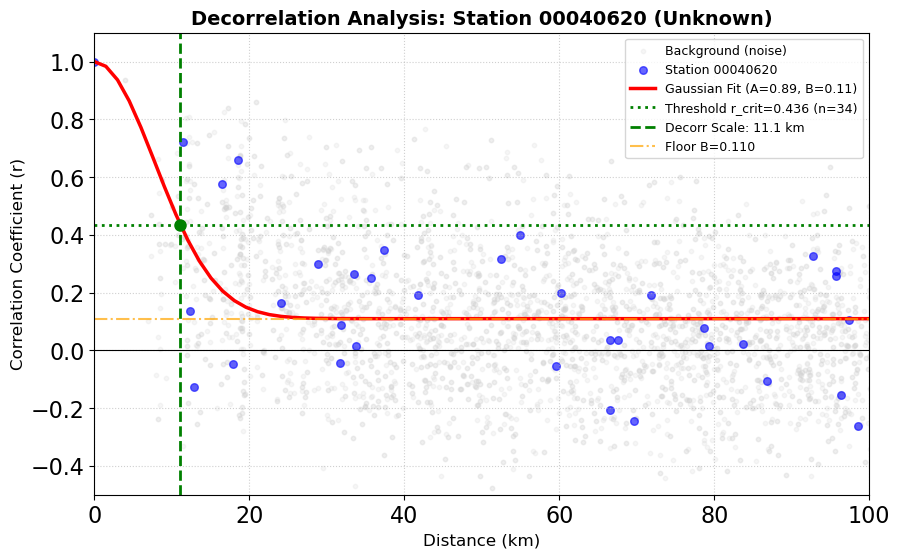

In [11]:
# --- TEST PLOT FOR SINGLE STATION (New Definition with Offset and Variable r_crit) ---
import matplotlib.pyplot as plt
import numpy as np

# A. Generate Global Background Sample (if not already present)
if 'bg_dists_sample' not in locals() or 'bg_corrs_sample' not in locals():
    print("Generating background sample for plot...")
    bg_dists_all = dist_matrix_km.values.flatten()
    bg_corrs_all = yearly_do_df.T.corr().values.flatten()
    
    mask = (~np.isnan(bg_dists_all)) & (~np.isnan(bg_corrs_all)) & (bg_dists_all > 0)
    bg_dists = bg_dists_all[mask]
    bg_corrs = bg_corrs_all[mask]
    
    if len(bg_dists) > 10000:
        idx = np.random.choice(len(bg_dists), 10000, replace=False)
        bg_dists_sample = bg_dists[idx]
        bg_corrs_sample = bg_corrs[idx]
    else:
        bg_dists_sample = bg_dists
        bg_corrs_sample = bg_corrs

# 1. Pick a station to test
test_station_idx = 105
if len(results_df) > 0:
    row = results_df.iloc[test_station_idx]
    station_id = row['Station_ID']
    decorr_dist = row['Decorrelation_Scale_km']
    A_fit = row['Amplitude_A']
    B_fit = row['Offset_B']
    dx_param = row['dx_param']
    r_crit = row['r_crit']
    n_neighbors = row['n_neighbors_100km']
    
    # Retrieve Division
    try:
        division_vals = summer_bottom_df.loc[summer_bottom_df['zettaicode'] == station_id, 'division'].unique()
        division = division_vals[0] if len(division_vals) > 0 else 'Unknown'
    except Exception as e:
        print(f"Could not retrieve division: {e}")
        division = 'Unknown'
    
    # Get specific station data
    target_series = yearly_do_df.loc[station_id]
    correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
    
    # Gather data points for this station
    plot_data = []
    for neighbor in yearly_do_df.index:
        valid_count = pd.concat([target_series, yearly_do_df.loc[neighbor]], axis=1).dropna().shape[0]
        if valid_count >= min_periods:
            if neighbor == station_id:
                plot_data.append({'dist': 0.0, 'corr': 1.0})
            else:
                d_val = dist_matrix_km.loc[station_id, neighbor]
                c_val = correlations[neighbor]
                if not np.isnan(d_val) and not np.isnan(c_val):
                    plot_data.append({'dist': d_val, 'corr': c_val})
    
    df_test = pd.DataFrame(plot_data)

    # Determine X axis limit
    if decorr_dist > 100:
        x_limit = np.ceil(2 * decorr_dist)
    else:
        x_limit = 100
    
    # Setup Figure
    plt.figure(figsize=(10, 6))
    
    # A. Plot Background
    if 'bg_dists_sample' in locals():
        plt.scatter(bg_dists_sample, bg_corrs_sample, color='lightgrey', alpha=0.2, s=10, label='Background (noise)')
    
    # B. Plot Target Station Data
    plt.scatter(df_test['dist'], df_test['corr'], color='blue', alpha=0.6, s=30, label=f'Station {station_id}')
    
    # C. Plot Fitted Gaussian Curve with Offset (r(x) = A * exp(-x²/dx²) + B)
    x_line = np.linspace(0, 300, 200)
    y_line = A_fit * np.exp(-(x_line / dx_param)**2) + B_fit
    plt.plot(x_line, y_line, color='red', linewidth=2.5, label=f'Gaussian Fit (A={A_fit:.2f}, B={B_fit:.2f})')
    
    # D. Plot Crossing Lines
    # Horizontal line at r = r_crit (station-specific threshold)
    plt.axhline(y=r_crit, color='green', linestyle=':', linewidth=2, label=f'Threshold r_crit={r_crit:.3f} (n={n_neighbors})')
    
    # Vertical line at the decorrelation distance
    if decorr_dist > 0:
        plt.axvline(x=decorr_dist, color='green', linestyle='--', linewidth=2, label=f'Decorr Scale: {decorr_dist:.1f} km')
        # Plot the intersection dot
        plt.plot(decorr_dist, r_crit, 'go', markersize=8, zorder=5)

    # E. Optional: Show where B (floor) is
    plt.axhline(y=B_fit, color='orange', linestyle='-.', linewidth=1.5, alpha=0.7, label=f'Floor B={B_fit:.3f}')

    # Aesthetics
    plt.title(f'Decorrelation Analysis: Station {station_id} ({division})', fontsize=14, fontweight='bold')
    plt.xlabel('Distance (km)', fontsize=12)
    plt.ylabel('Correlation Coefficient (r)', fontsize=12)
    plt.axhline(0, color='black', linewidth=0.8)
    plt.ylim(-0.5, 1.1)
    plt.xlim(0, x_limit)
    plt.legend(loc='upper right', fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.6)
    
    plt.show()
else:
    print("No results found in results_df")

In [12]:
# Loop generation (Production) - Updated for Offset Model and Variable r_crit
import os
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Ensure output directory exists (figures saved in seasonal subsetdirectory)
subset_name = Path(subset_dir).name
output_dir = ProjectPaths.FIGURES_DIR / subset_name / 'distance_correlation_station'
output_dir.mkdir(parents=True, exist_ok=True)

# --- GLOBAL BACKGROUND SAMPLE ---
print("Generating global background sample...")
bg_dists = dist_matrix_km.values.flatten()
bg_corrs = yearly_do_df.T.corr().values.flatten() 

mask = (~np.isnan(bg_dists)) & (~np.isnan(bg_corrs)) & (bg_dists > 0)
bg_dists = bg_dists[mask]
bg_corrs = bg_corrs[mask]

if len(bg_dists) > 10000:
    idx = np.random.choice(len(bg_dists), 10000, replace=False)
    bg_dists_sample = bg_dists[idx]
    bg_corrs_sample = bg_corrs[idx]
else:
    bg_dists_sample = bg_dists
    bg_corrs_sample = bg_corrs

print("Starting generation loop...")

# Iterate through results_df
for index, row in results_df.iterrows():
    station_id = row['Station_ID']
    decorr_dist = row['Decorrelation_Scale_km']
    A_fit = row['Amplitude_A']
    B_fit = row['Offset_B']
    dx_param = row['dx_param']
    r_crit = row['r_crit']
    n_neighbors = row['n_neighbors_100km']
    
    # Retrieve Division
    try:
        division_vals = summer_bottom_df.loc[summer_bottom_df['zettaicode'] == station_id, 'division'].unique()
        division = division_vals[0] if len(division_vals) > 0 else 'Unknown'
    except Exception as e:
        division = 'Unknown'
    
    # Get specific station data
    target_series = yearly_do_df.loc[station_id]
    correlations = yearly_do_df.corrwith(target_series, axis=1, drop=True)
    
    # Gather data points
    plot_data = []
    for neighbor in yearly_do_df.index:
        valid_count = pd.concat([target_series, yearly_do_df.loc[neighbor]], axis=1).dropna().shape[0]
        if valid_count >= min_periods:
            if neighbor == station_id:
                plot_data.append({'dist': 0.0, 'corr': 1.0})
            else:
                d_val = dist_matrix_km.loc[station_id, neighbor]
                c_val = correlations[neighbor]
                if not np.isnan(d_val) and not np.isnan(c_val):
                    plot_data.append({'dist': d_val, 'corr': c_val})
                    
    df_plot = pd.DataFrame(plot_data)
    if df_plot.empty: continue

    # Determine X axis limit
    if decorr_dist > 100:
        x_limit = np.ceil(2 * decorr_dist)
    else:
        x_limit = 100
    
    # Setup Figure
    plt.figure(figsize=(10, 6))
    
    # A. Plot Background
    plt.scatter(bg_dists_sample, bg_corrs_sample, color='lightgrey', alpha=0.2, s=10, label='Background (noise)')
    
    # B. Plot Target Station Data
    plt.scatter(df_plot['dist'], df_plot['corr'], color='blue', alpha=0.6, s=30, label=f'Station {station_id}')
    
    # C. Plot Fitted Gaussian Curve with Offset (r(x) = A * exp(-x²/dx²) + B)
    x_line = np.linspace(0, 300, 200)
    y_line = A_fit * np.exp(-(x_line / dx_param)**2) + B_fit
    plt.plot(x_line, y_line, color='red', linewidth=2.5, label=f'Gaussian Fit (A={A_fit:.2f}, B={B_fit:.2f})')
    
    # D. Plot Crossing Lines (station-specific r_crit)
    plt.axhline(y=r_crit, color='green', linestyle=':', linewidth=2, label=f'Threshold r_crit={r_crit:.3f} (n={n_neighbors})')
    
    if decorr_dist > 0:
        plt.axvline(x=decorr_dist, color='green', linestyle='--', linewidth=2, label=f'Decorr Scale: {decorr_dist:.1f} km')
        plt.plot(decorr_dist, r_crit, 'go', markersize=8, zorder=5)

    # E. Show floor B
    plt.axhline(y=B_fit, color='orange', linestyle='-.', linewidth=1.5, alpha=0.7, label=f'Floor B={B_fit:.3f}')
        
    # Aesthetics
    plt.title(f'Decorrelation Analysis: Station {station_id} ({division})', fontsize=14, fontweight='bold')
    plt.xlabel('Distance (km)', fontsize=12)
    plt.ylabel('Correlation Coefficient (r)', fontsize=12)
    plt.axhline(0, color='black', linewidth=0.8)
    plt.ylim(-0.5, 1.1)
    plt.xlim(0, x_limit)
    plt.legend(loc='upper right', fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.6)
    
    # Save
    plt.savefig(output_dir / f"{station_id}.png", dpi=100)
    plt.close()

print("All plots generated.")

Generating global background sample...
Starting generation loop...
All plots generated.


## 5. Visualization - Summary Maps and Plots

A summary of the calculated Decorrelation Scales across the region.

1.  **Bar Plot**: Decorrelation Scale by Station.
2.  **Map**: Spatial distribution of decorrelation scales with a colorbar.

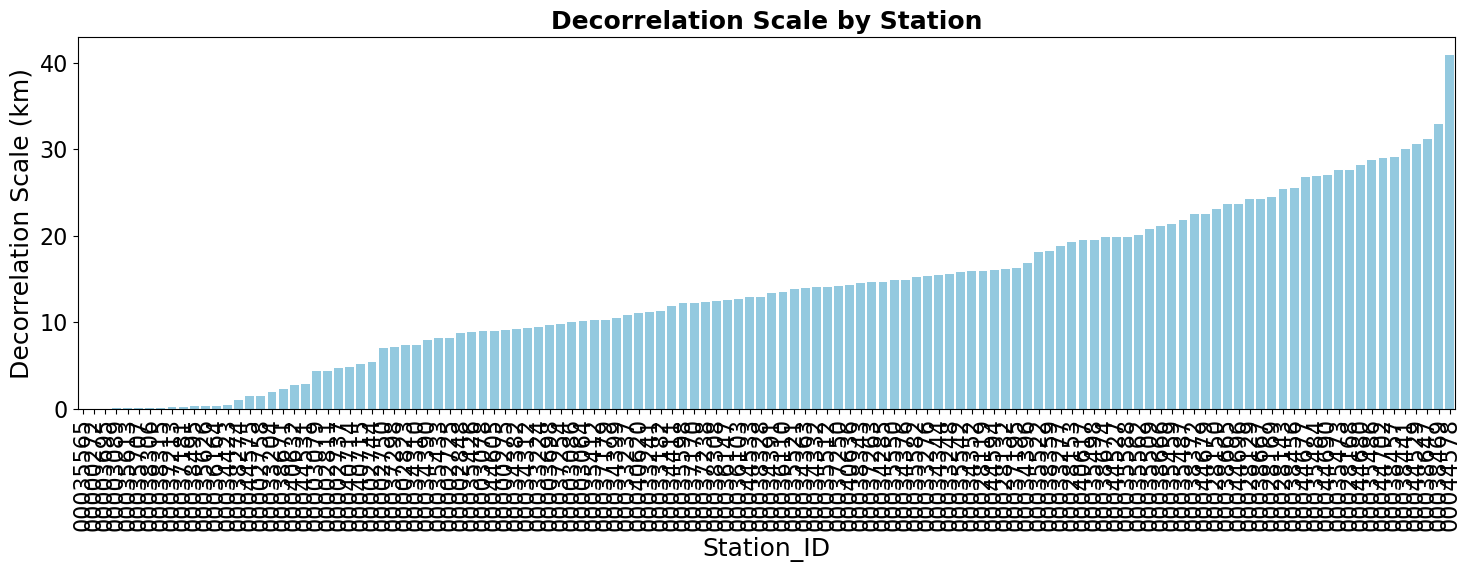

In [13]:
# Bar Plot
plt.figure(figsize=(15, 6))
sns.barplot(data=results_df.sort_values('Decorrelation_Scale_km'), x='Station_ID', y='Decorrelation_Scale_km', color='skyblue')
plt.xticks(rotation=90)
plt.title('Decorrelation Scale by Station')
plt.ylabel('Decorrelation Scale (km)')
plt.tight_layout()
plt.show()

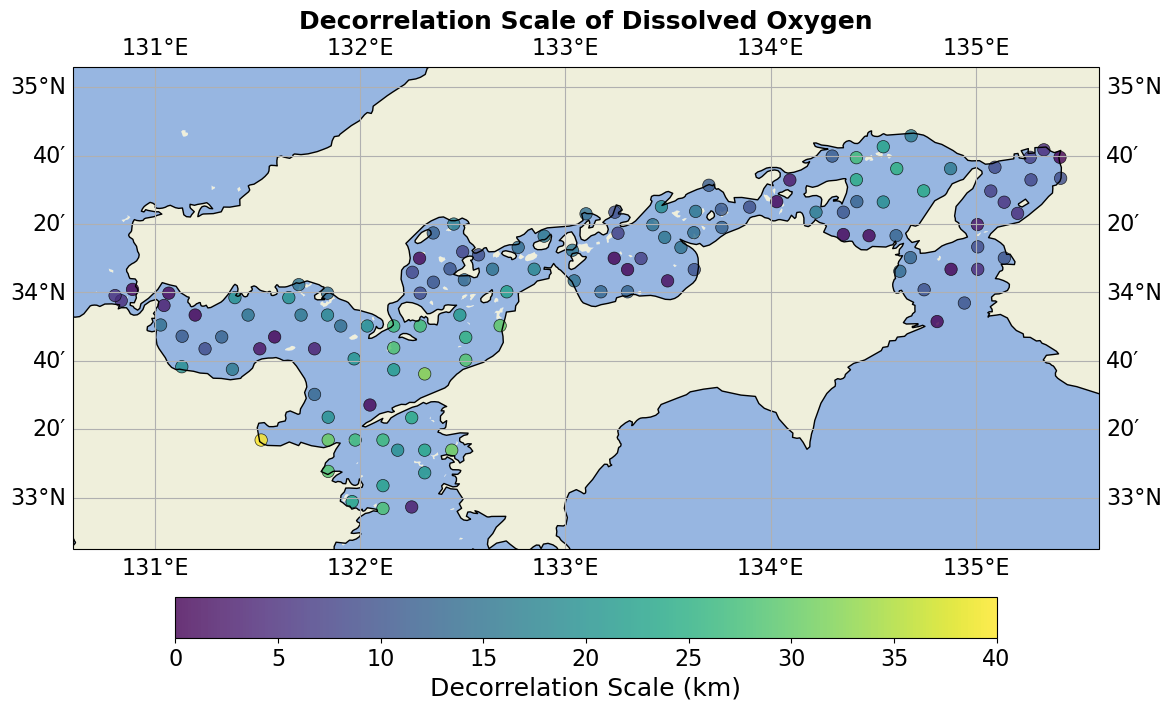

In [14]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Merge results with coordinates for plotting
# station_locs was indexed by zettaicode
results_gdf = station_locs.loc[results_df['Station_ID']].copy()
results_gdf['dx'] = results_df.set_index('Station_ID')['Decorrelation_Scale_km']

# Set min and max limit to exclude outliers
vmin_val = 0
vmax_val = 40

# --- 1. Map of Decorrelation Scale ---
fig = plt.figure(figsize=(12, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.coastlines()
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)

# Plot points colored by Decorrelation Scale
sc = ax.scatter(
    results_gdf['longitude'], 
    results_gdf['latitude'], 
    c=results_gdf['dx'], 
    cmap='viridis', 
    vmin=vmin_val,
    vmax=vmax_val,
    s=80, 
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    edgecolors='black',
    linewidth=0.5
)

# Add Colorbar
plt.colorbar(sc, ax=ax, label='Decorrelation Scale (km)', orientation='horizontal', pad=0.05, shrink=0.8)
ax.set_title('Decorrelation Scale of Dissolved Oxygen', fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()

# Extra: Bullseye map

This is another version of the map that shows a circle of influence of the stations with the high decorrelation scale (or low, depending on the setting). The radius of the inner circle represents the decorrelation scale of that specific station.

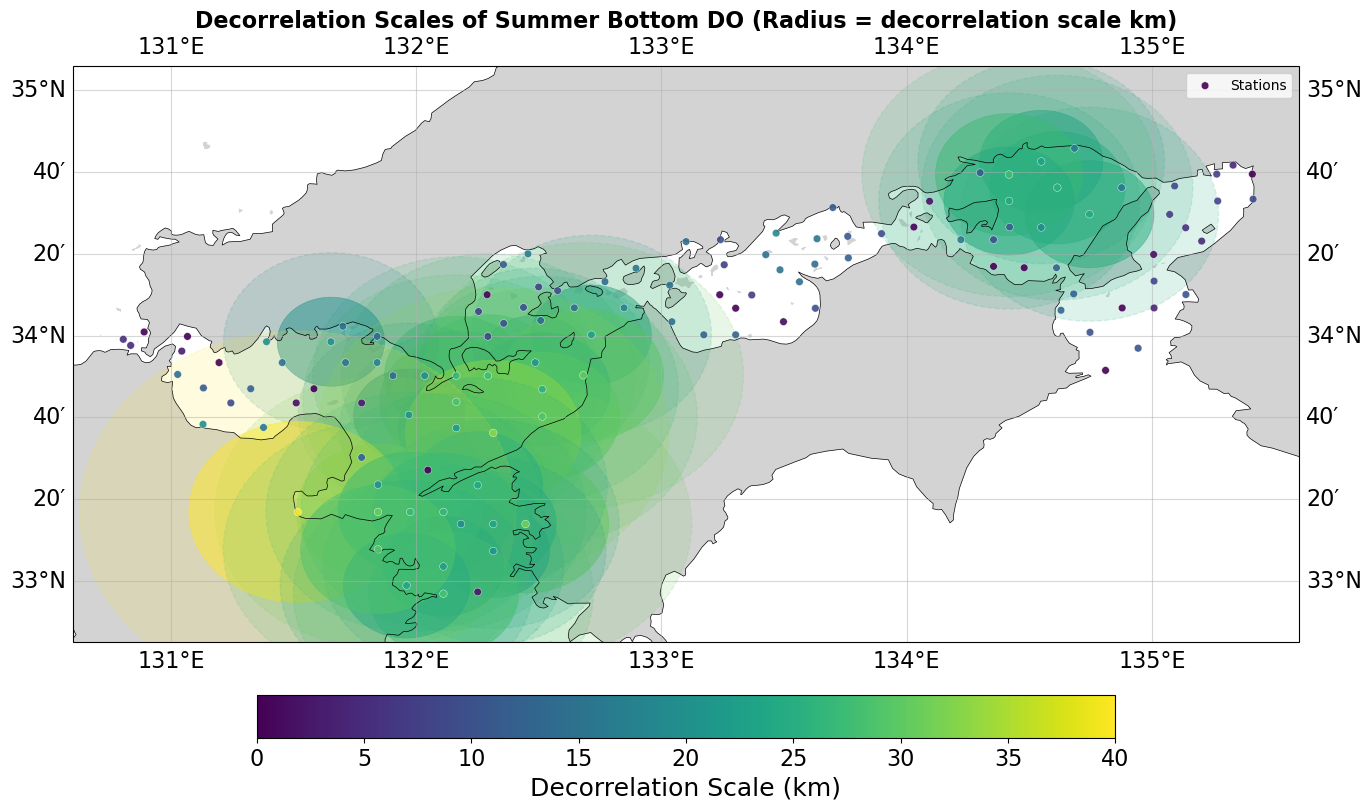

In [15]:
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection

# Merge results with coordinates for plotting
results_gdf = station_locs.loc[results_df['Station_ID']].copy()
results_gdf['dx'] = results_df.set_index('Station_ID')['Decorrelation_Scale_km']

# Set min and max limit for colormap
vmin_val = 0
vmax_val = 40  # Adjust based on your data range

# Conversion factor: km to degrees (approximate at ~34°N latitude)
# 1 degree latitude ≈ 111 km, 1 degree longitude ≈ 91 km at 34°N
km_per_deg_lat = 111.0
km_per_deg_lon = 111.0 * np.cos(np.radians(34.0))  # ~91 km

# --- BULLSEYE MAP ---
fig = plt.figure(figsize=(14, 11))
ax = plt.axes(projection=ccrs.PlateCarree())

# Set extent for Seto Inland Sea
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='white')
ax.coastlines(linewidth=0.5)
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, alpha=0.5)

# Get colormap
cmap = plt.cm.viridis
norm = plt.Normalize(vmin=vmin_val, vmax=vmax_val)

# Draw bullseye circles for each station
for idx, row in results_gdf.iterrows():
    lon = row['longitude']
    lat = row['latitude']
    dx_km = row['dx']
    
    if np.isnan(dx_km) or dx_km <= 20 or dx_km >=45:
        continue
    
    # Convert km to degrees (approximate ellipse to account for lat/lon distortion)
    radius_deg_lat = dx_km / km_per_deg_lat
    radius_deg_lon = dx_km / km_per_deg_lon
    
    # Get color based on decorrelation scale
    color = cmap(norm(dx_km))
    
    # Outer Circle: 2x decorrelation scale (Max Reach zone)
    outer_ellipse = mpatches.Ellipse(
        (lon, lat), 
        width=4 * radius_deg_lon,   # 2x radius = 2x diameter factor
        height=4 * radius_deg_lat,
        facecolor=color,
        edgecolor=color,
        alpha=0.15,
        linestyle='--',
        linewidth=1,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(outer_ellipse)
    
    # Inner Circle: 1x decorrelation scale (Core Confidence zone)
    inner_ellipse = mpatches.Ellipse(
        (lon, lat), 
        width=2 * radius_deg_lon,   # 1x radius
        height=2 * radius_deg_lat,
        facecolor=color,
        edgecolor=color,
        alpha=0.5,
        linewidth=0.5,
        transform=ccrs.PlateCarree()
    )
    ax.add_patch(inner_ellipse)

# Plot station points on top
ax.scatter(
    results_gdf['longitude'], 
    results_gdf['latitude'], 
    c=results_gdf['dx'],
    cmap='viridis',
    vmin=vmin_val,
    vmax=vmax_val,
    s=30, 
    alpha=0.9,
    transform=ccrs.PlateCarree(),
    edgecolors='white',
    linewidth=0.3,
    zorder=10,
    label='Stations'
)

# Add Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, label='Decorrelation Scale (km)', orientation='horizontal', pad=0.05, shrink=0.7)

# Title and legend
ax.set_title('Decorrelation Scales of Summer Bottom DO (Radius = decorrelation scale km)', fontsize=16, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.show()

GEBCO Grid data not found in this notebook. Skipping bathymetry layer.


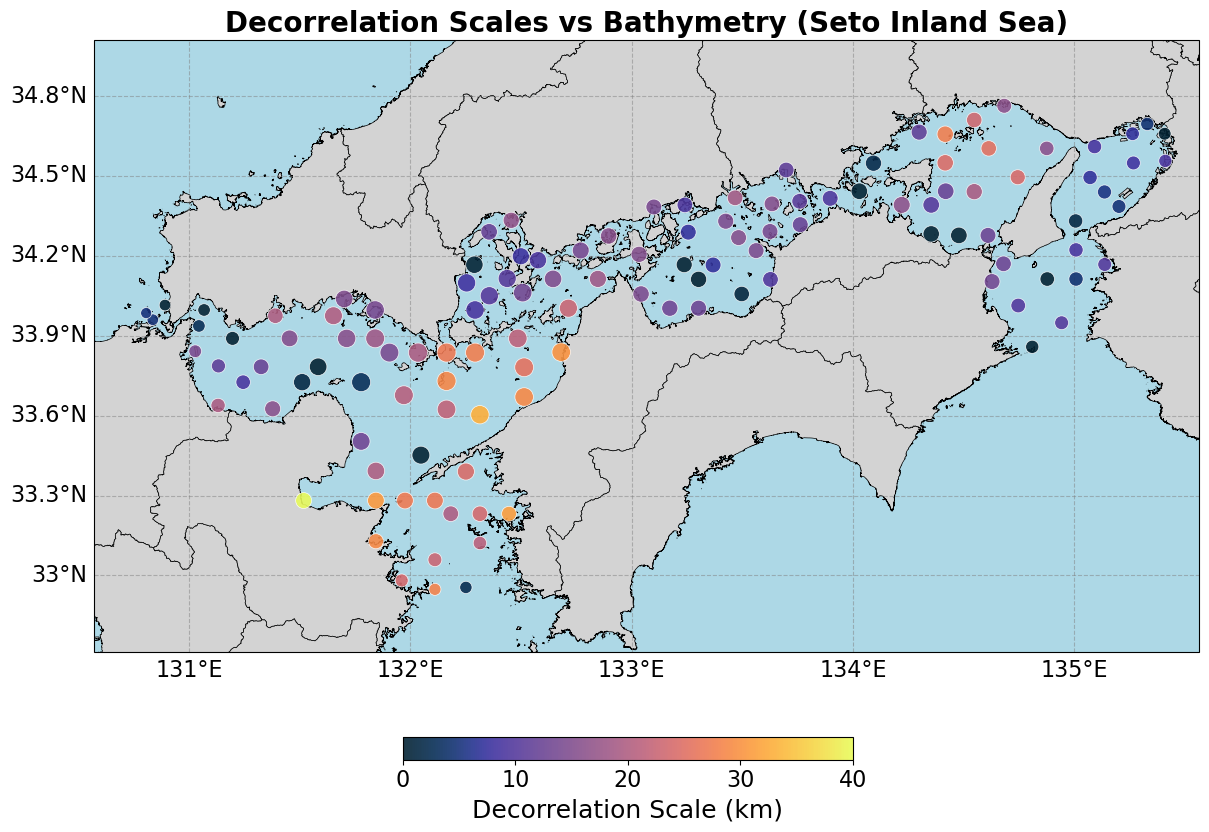

In [16]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cmocean
from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# Apply the global project style as per SIS Mapping Standard
plt.style.use('../../project_style.mplstyle')

# 1. Prepare Data
# Map to the existing results dataframe generated by the loop in this notebook
df_decorr = results_df.copy()
# Ensure Station_ID is formatted consistently
if 'Station_ID' not in df_decorr.columns:
    df_decorr['Station_ID'] = df_decorr.index.astype(str).str.zfill(8)
else:
    df_decorr['Station_ID'] = df_decorr['Station_ID'].astype(str).str.zfill(8)

# merged_gdf should already be loaded in this notebook's environment
gdf_stations = merged_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates(subset='zettaicode')
gdf_stations = gdf_stations.rename(columns={'zettaicode': 'Station_ID'})
gdf_stations['Station_ID'] = gdf_stations['Station_ID'].astype(str).str.zfill(8)

df_plot = df_decorr.merge(gdf_stations, on='Station_ID', how='inner')

# 2. Get Standard Map Extents (from SIS water mask)
water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / "sea_area_mask_simplified.shp"
sis_water = gpd.read_file(water_boundary_path).to_crs("EPSG:4326")
bounds = sis_water.total_bounds
# [xmin, xmax, ymin, ymax] for Cartopy (Updated as per documentation)
extent = [bounds[0]+0.1, bounds[2]+0.1, bounds[1]-0, bounds[3]+0.2]

# 3. Initialize Plot
# Calculate dynamic height based on geographic extent to remove excess vertical white space
width_deg = extent[1] - extent[0]
height_deg = extent[3] - extent[2]
aspect_ratio = height_deg / width_deg
fig_width = 15
# Map height + 2.1" buffer for title and colorbars
fig_height = (fig_width * aspect_ratio) + 2.1 

fig, ax = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN) 

# --- Z-ORDER 0.5: BATHYMETRY ---
# Safely handle bathymetry grid if it wasn't calculated in this specific notebook
try:
    im_gebco = ax.pcolormesh(
        lon_g, lat_g, depth_g, 
        cmap=cmocean.cm.deep,
        vmin=0, vmax=180, 
        transform=ccrs.PlateCarree(),
        zorder=0.5
    )
    has_gebco = True
except NameError:
    print("GEBCO Grid data not found in this notebook. Skipping bathymetry layer.")
    has_gebco = False

# --- Z-ORDER 1: LAND MASK ---
land_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary_2.shp"
sis_land = gpd.read_file(land_path).to_crs("EPSG:4326")
sis_land.plot(
    ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE,
    linewidth=MappingConfig.LINEWIDTH_LAND, zorder=MappingConfig.ZORDER_LAND,
    transform=ccrs.PlateCarree()
)

# --- Z-ORDER 2: GRIDLINES ---
gl = ax.gridlines(draw_labels=True, linestyle='--', color='gray', alpha=0.5, zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False
# SIS Standard: Tick Labels = 16
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}

# --- Z-ORDER 5: DECORRELATION DATA OVERLAY ---
sc = ax.scatter(
    df_plot.longitude, df_plot.latitude, 
    c=df_plot.Decorrelation_Scale_km, 
    s=df_plot.n_neighbors_100km * 3 if 'n_neighbors_100km' in df_plot.columns else 50, # fallback size
    cmap=cmocean.cm.thermal,
    vmin=0, vmax=40, 
    alpha=0.9, edgecolors='white', linewidths=0.5,
    transform=ccrs.PlateCarree(), 
    zorder=MappingConfig.ZORDER_OBSERVATIONS
)

ax.set_extent(extent, crs=ccrs.PlateCarree())
# SIS Standard: Title = 20, Bold
ax.set_title(f"Decorrelation Scales vs Bathymetry ({TARGET_REGION})", fontsize=20, fontweight='bold')

# 4. Add Colorbars
# Subplots adjust to minimize space; bottom margin reduced to pull colorbars up
plt.subplots_adjust(bottom=0.20)

# Colorbar axes: [left, bottom, width, height]
# SIS Standard: Axis Labels = 18, Tick Labels = 16
if has_gebco:
    cbar_ax_bathy = fig.add_axes([0.15, 0.08, 0.3, 0.025]) 
    cb1 = fig.colorbar(im_gebco, cax=cbar_ax_bathy, orientation='horizontal')
    cb1.set_label('Depth (m)', fontsize=18)
    cb1.ax.tick_params(labelsize=16)

cbar_ax_decorr = fig.add_axes([0.55, 0.08, 0.3, 0.025] if has_gebco else [0.35, 0.08, 0.3, 0.025]) 
cb2 = fig.colorbar(sc, cax=cbar_ax_decorr, orientation='horizontal')
cb2.set_label('Decorrelation Scale (km)', fontsize=18)
cb2.ax.tick_params(labelsize=16)

plt.show()

In [17]:
# --- Save Results for DVC Pipeline ---

# 1. Save Distance Matrix (shared — stays in data/processed/)
if 'dist_matrix_km' in locals():
    dist_matrix_path = ProjectPaths.DIST_MATRIX_FILE
    dist_matrix_km.to_csv(dist_matrix_path)
    print(f"Saved distance matrix to {dist_matrix_path}")

# 2. Save Decorrelation Scales into the subset directory
if 'results_df' in locals():
    decorrelation_path = Path(subset_dir) / 'stations_decorrelation_scale.csv'
    results_df.to_csv(decorrelation_path, index=False)
    print(f"Saved decorrelation scales to {decorrelation_path}")

Saved distance matrix to /home/reyha/SIS_Analysis_WSL/data/processed/dist_matrix_km.csv
Saved decorrelation scales to /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/stations_decorrelation_scale.csv
